# 01 — Qualidade dos dados e dados faltantes

**Para que serve este notebook.** Antes de tirar qualquer conclusão sobre os cartórios de Minas Gerais, precisamos saber **o quanto podemos confiar em cada dado**. Aqui medimos, fonte por fonte e campo por campo:

1. o que **falta** (campos vazios, "não informado", zeros que provavelmente significam "não declarado");
2. os **valores atípicos** (números muito fora do padrão), com o critério usado;
3. se as **fontes concordam entre si** (CNJ × RAIS × CNPJ × BI do CNJ).

No fim há uma **tabela de conclusão**: o que é confiável, o que é estimado e o tamanho de cada problema.

**As fontes** (todas públicas e gratuitas; detalhes em `docs/dicionario_dados.md`):

| Fonte | O que traz | Data de referência |
|---|---|---|
| CNJ, Justiça Aberta (API) | cadastro das serventias, atribuições, situação, arrecadação semestral, colaboradores | coleta de 17 e 18/10/2026 |
| CNJ, BI do Painel das Serventias | arrecadação e repasse por serventia (exportação manual) | até 31/12/2025 |
| RAIS 2025 (Ministério do Trabalho) | vínculos de emprego dos cartórios, com salário e tempo de casa | 31/12/2025 |
| CNPJ (Receita Federal) | estabelecimentos com CNAE 6912-5/00 (cartórios) | outubro de 2026 |
| IBGE | municípios, regiões e população | malha 2022 |

**Glossário rápido** (os termos são explicados de novo onde aparecem):
- **Serventia** = cartório. Cada uma tem um código do CNJ, o **CNS**.
- **Provida** = tem titular aprovado em concurso. **Vaga** = sem titular; um interino responde por ela. **Outras** = sob intervenção ou em conversão em diligência.
- **Classe 1** = arrecadação média de até R$ 300 mil por semestre (Prov. 213, com a redação do Prov. 243). O Prov. 227 **dispensa** a Classe 1 do seguro-garantia; por isso a receita é o dado mais importante para saber quem é obrigado.
- **Passivo** = o valor estimado pelo modelo do projeto para as dívidas trabalhistas (férias, 13º, rescisão) dos empregados CLT de cada cartório.

> Este notebook só **lê** os dados (conexão somente leitura). Os gráficos também são gravados em PNG em `docs/qa/analises/`.

In [1]:
import sys
from pathlib import Path

raiz = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(raiz))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src.analise import dados, estatistica as est, graficos as g
from src.notebooks import conectar, ler

g.estilo()
con = conectar()
sv = dados.serventias(con)            # serventias ativas com o resultado do modelo (cenário base, regra v2)
ar = dados.serie_arrecadacao(con)     # arrecadação semestral de cada serventia, 2007 a 2026
carga = ler("SELECT max(executado_em) FROM gold.execucao", con=con).iloc[0, 0]
print(f"Carga de {carga:%d/%m/%Y}: {g.num(len(sv))} serventias ativas, {ar.periodo.nunique()} semestres "
      f"({ar.periodo.min()} a {ar.periodo.max()}), {g.num(len(ar))} linhas de arrecadação.")

Carga de 19/10/2026: 2.525 serventias ativas, 39 semestres (2007-1 a 2026-1), 98.475 linhas de arrecadação.


## 1. Arrecadação: o que falta em cada semestre

**A pergunta.** Em cada semestre, quantas serventias ativas **não informaram** a arrecadação, quantas declararam **zero** e quantas têm **valores em conflito** na fonte?

**O método.** Contagem simples, semestre a semestre, das 2.525 serventias ativas:
- **não informado:** a API do CNJ traz o texto "NÃO INFORMADO" no lugar do valor;
- **zero:** o valor declarado é R$ 0,00. Um cartório em funcionamento sem arrecadar nada num semestre inteiro é improvável; por isso o projeto trata o zero dos dois semestres de 2025 como "não declarado" (decisão D-013);
- **conflito:** a API traz **dois valores diferentes** para a mesma serventia e o mesmo semestre (D-014).

Exemplo pequeno: se, num semestre, 2.525 serventias aparecem e 135 declararam zero, a taxa de zeros é 135 ÷ 2.525 = 5,3%.

Por que contar em %: o número de serventias é quase o mesmo em todos os semestres (o histórico vem só das que estão ativas hoje), então a % compara bem os períodos.

,periodo,serventias,nao_informado,zero,conflito,total,pct_zero,pct_nao_informado
0,2022-2,2.525,0,53,1,"R$ 2,0 bi","2,1%","0,0%"
1,2023-1,2.525,0,55,0,"R$ 1,8 bi","2,2%","0,0%"
2,2023-2,2.525,0,58,0,"R$ 2,2 bi","2,3%","0,0%"
3,2024-1,2.525,0,56,2,"R$ 2,0 bi","2,2%","0,0%"
4,2024-2,2.525,0,86,3,"R$ 2,5 bi","3,4%","0,0%"
5,2025-1,2.525,0,135,2,"R$ 2,4 bi","5,3%","0,0%"
6,2025-2,2.525,0,143,0,"R$ 3,1 bi","5,7%","0,0%"
7,2026-1,2.525,57,48,0,"R$ 3,2 bi","1,9%","2,3%"


Zeros em 2007: 571, dos quais 276 vêm antes do 1º valor > 0 declarado pela serventia.
Zeros em 2025: 278, dos quais 0 vêm antes do 1º valor > 0 declarado pela serventia.


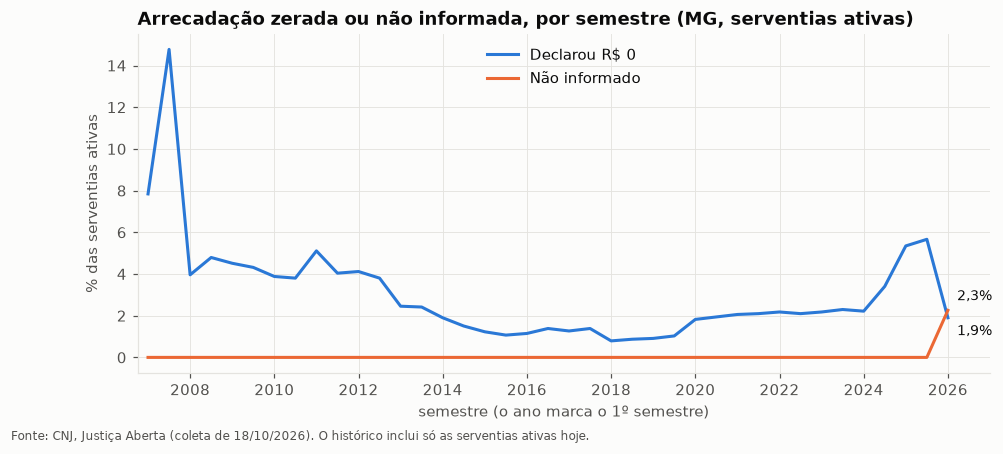

In [2]:
por_periodo = ar.groupby("periodo").agg(
    serventias=("cns", "size"),
    nao_informado=("informado", lambda s: int((~s).sum())),
    zero=("arrecadacao", lambda s: int((s == 0).sum())),
    conflito=("conflito_fonte", "sum"),
    total=("arrecadacao", "sum"),
)
por_periodo["pct_zero"] = por_periodo["zero"] / por_periodo["serventias"]
por_periodo["pct_nao_informado"] = por_periodo["nao_informado"] / por_periodo["serventias"]
display(g.tabela(por_periodo.tail(8).reset_index(),
                 {"serventias": "int", "nao_informado": "int", "zero": "int", "conflito": "int", "total": "reais",
                  "pct_zero": "pct", "pct_nao_informado": "pct"}))

# zero "antes de existir": o semestre vem antes do 1º valor > 0 que a serventia declarou (provavelmente ainda não existia
# ou não declarava); a série traz uma linha por semestre para toda serventia ativa hoje
ordenada = ar.sort_values(["cns", "ano", "semestre"])
ja_declarou = ordenada.groupby("cns")["arrecadacao"].transform(lambda v: (v > 0).cummax())
zeros_iniciais = ordenada[(ordenada.arrecadacao == 0) & ~ja_declarou]
for ano in (2007, 2025):
    z = ordenada[(ordenada.ano == ano) & (ordenada.arrecadacao == 0)]
    print(f"Zeros em {ano}: {g.num(len(z))}, dos quais {g.num(z.index.isin(zeros_iniciais.index).sum())} vêm antes do "
          "1º valor > 0 declarado pela serventia.")

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(por_periodo))
ax.plot(x, 100 * por_periodo["pct_zero"], color=g.CORES[0], label="Declarou R$ 0")
ax.plot(x, 100 * por_periodo["pct_nao_informado"], color=g.CORES[1], label="Não informado")
for serie, dy in (("pct_zero", -9), ("pct_nao_informado", 9)):
    ax.annotate(g.pct(por_periodo[serie].iloc[-1]), (x[-1], 100 * por_periodo[serie].iloc[-1]),
                xytext=(6, dy), textcoords="offset points", color=g.TEXTO, va="center", fontsize=9)
g.eixo_periodos(ax, list(por_periodo.index))
ax.set_xlim(-0.5, len(x) + 1)
ax.set_xlabel("semestre (o ano marca o 1º semestre)")
ax.set_ylabel("% das serventias ativas")
ax.set_title("Arrecadação zerada ou não informada, por semestre (MG, serventias ativas)")
ax.legend(loc="upper center")
g.nota(fig, "Fonte: CNJ, Justiça Aberta (coleta de 18/10/2026). O histórico inclui só as serventias ativas hoje.")
g.salvar(fig, "01_arrecadacao_zero_e_nao_informado_por_semestre")
plt.show()

**Como ler.** Cada ponto é um semestre. A linha azul é a % de serventias que declararam R$ 0; a laranja, a % sem informação.

**O que encontramos.**
- Até 2024 o "não informado" é **zero** em todos os semestres; ele só aparece em **2026-1** (57 serventias, 2,3%), provavelmente porque o semestre acabou de fechar e nem todas declararam ainda.
- Os **zeros** caem de 8% a 15% em 2007 para 1% a 2% entre 2018 e 2024-1, e **sobem a partir de 2024-2** (3,4%), chegando a **5,3% e 5,7% em 2025** (135 e 143 serventias). Essa alta é justamente no ano usado para o enquadramento da classe (D-010). Em 2026-1 os zeros voltam a 1,9%.
- Os zeros do começo da série **não são todos falta de declaração**: dos 571 zeros de 2007, **276 (cerca de metade)** vêm antes do primeiro valor declarado pela serventia, ou seja, ela provavelmente ainda não existia ou não declarava (a série traz uma linha por semestre para toda serventia ativa hoje). Em 2025, nenhum zero é desse tipo: são serventias que já declaravam e pararam.
- Os **conflitos** são raros (poucas serventias por semestre) e, em 2025, afetam só 2 serventias.

**O que significa para o mercado do Prov. 227.** A classe de cada cartório (e, portanto, se ele é obrigado a contratar o seguro) depende da arrecadação de 2025. Os zeros de 2025 são o maior buraco dessa informação: quem zerou os dois semestres fica com **classe indeterminada** e entra no modelo com um peso, não como "obrigado" ou "dispensado" (seção 2).

**Limitações.** O histórico só traz as serventias **ativas hoje**; as que fecharam no passado não aparecem, então a série não mostra a qualidade dos dados daquelas serventias. A alta dos zeros em 2025 pode ser atraso de declaração (a fonte pode ser corrigida depois) e não fechamento de cartórios.

## 2. Receita de referência de 2025: quantas serventias têm a classe calculável

**A pergunta.** Para quantas serventias conseguimos calcular a **receita de referência** (a média semestral de 2025) que define a classe?

**O método.** A regra do projeto (D-010, D-013, D-014), aplicada a cada serventia:

| Situação dos dois semestres de 2025 | Receita de referência | Nome no banco |
|---|---|---|
| os dois com valor > 0 | média dos dois | `media_2_semestres` |
| só um com valor > 0 (o outro zero) | o valor desse semestre | `um_semestre` |
| zero nos dois | nenhuma: classe indeterminada | `zero_nos_dois_semestres` |
| algum semestre em conflito | nenhuma: classe indeterminada | `conflito_fonte` |

Exemplo: semestres de R$ 200 mil e R$ 400 mil → média R$ 300 mil → Classe 1 (até R$ 300 mil). Semestres de R$ 0 e R$ 400 mil → usa R$ 400 mil → Classe 2.

Quebramos por **situação** (provida, vaga, outras) porque a vacância muda a leitura do risco: numa serventia vaga, a delegação está com um interino.

situacao,origem_receita,outras,provida,vaga,total,pct_do_total
0,conflito_fonte,0,0,2,2,"0,1%"
1,media_2_semestres,28,1.547,748,2.323,"92,0%"
2,um_semestre,10,80,34,124,"4,9%"
3,zero_nos_dois_semestres,3,27,46,76,"3,0%"
4,total,41,1.654,830,2.525,"100,0%"


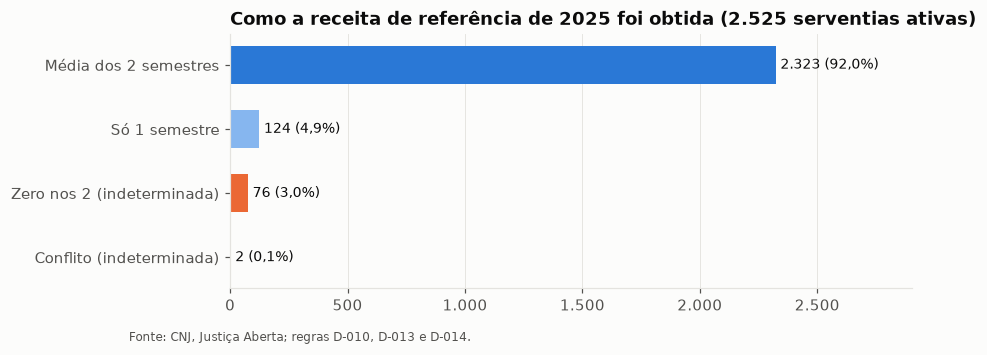

In [3]:
origem = pd.crosstab(sv["origem_receita"], sv["situacao"], margins=True, margins_name="total")
origem["pct_do_total"] = origem["total"] / len(sv)
display(g.tabela(origem.reset_index(), {c: "int" for c in ["provida", "vaga", "outras", "total"]} | {"pct_do_total": "pct"}))

ordem = ["media_2_semestres", "um_semestre", "zero_nos_dois_semestres", "conflito_fonte"]
rotulos = ["Média dos 2 semestres", "Só 1 semestre", "Zero nos 2 (indeterminada)", "Conflito (indeterminada)"]
n = sv["origem_receita"].value_counts().reindex(ordem)
fig, ax = plt.subplots(figsize=(8, 3))
cores = [g.AZUL["medio"], g.AZUL["claro"], g.CORES[1], g.CORES[1]]
ax.barh(rotulos[::-1], n.values[::-1], color=cores[::-1], height=0.6)
for i, v in enumerate(n.values[::-1]):
    ax.text(v + 20, i, f"{g.num(v)} ({g.pct(v / len(sv))})", va="center", fontsize=9, color=g.TEXTO)
ax.set_xlim(0, n.max() * 1.25)
ax.grid(axis="y", visible=False)
g.eixo_num(ax, "x")
ax.set_title("Como a receita de referência de 2025 foi obtida (2.525 serventias ativas)")
g.nota(fig, "Fonte: CNJ, Justiça Aberta; regras D-010, D-013 e D-014.")
g.salvar(fig, "01_receita_referencia_2025_origem")
plt.show()

**Como ler.** A barra azul-escura é o caso "bom" (dois semestres informados). As laranjas são as serventias **sem classe** calculável.

**O que encontramos.** 92,0% das serventias (2.323) têm os dois semestres; 4,9% (124) têm só um; **3,1% (78) ficam com classe indeterminada**: 76 (3,0%) por zero nos dois semestres e 2 (0,1%) por conflito. A cobertura total da receita (96,9%) passa no critério de qualidade do projeto (≥ 95%, `config/qualidade.yaml`).

As **vagas** concentram os problemas: são 33% das serventias, mas 46 das 76 com zero nos dois semestres (61%) e as 2 com conflito.

**O que significa para o Prov. 227.** As 78 indeterminadas entram no modelo com um peso (a probabilidade de não serem Classe 1, estimada pelas que têm receita). É por isso que o número de obrigadas do painel tem casa decimal (≈ 1.121,3): cada indeterminada soma uma fração, não 0 nem 1. Se todas fossem obrigadas, o universo subiria; se nenhuma fosse, cairia. Essa é parte da diferença entre os cenários mínimo, base e máximo do painel.

**Limitações.** "Só 1 semestre" supõe que o semestre zerado é falta de declaração; se o cartório realmente não arrecadou, a média verdadeira é a metade, e a classe pode estar superestimada para essas 124 serventias.

## 3. Empregados CLT: o que falta e o que é zero

**A pergunta.** Quantas serventias não informaram os colaboradores ao CNJ, e quantas informaram **zero** empregados CLT?

**O método.** Contagem na tabela de colaboradores do CNJ (`dados-complementares` da API). O número de **empregados CLT** é a base do passivo trabalhista: sem CLT, o passivo estimado é zero (D-003: só os CLT entram no passivo; estatutários, estagiários e terceirizados não).

In [4]:
clt = pd.DataFrame({
    "não informou os colaboradores": ~sv["colaboradores_informados"].fillna(False).astype(bool),
    "informou zero CLT": sv["clt"].eq(0),
    "1 ou 2 CLT": sv["clt"].between(1, 2),
    "3 ou mais CLT": sv["clt"].ge(3),
})
tab = pd.DataFrame({sit: clt[sv["situacao"] == sit].sum() for sit in ["provida", "vaga", "outras"]})
tab["total"] = tab.sum(axis=1)
tab["pct_do_total"] = tab["total"] / len(sv)
display(g.tabela(tab.reset_index(names="empregados CLT"),
                 {c: "int" for c in ["provida", "vaga", "outras", "total"]} | {"pct_do_total": "pct"}))
print(f"Passivo zero no modelo: {g.num((sv.passivo == 0).sum())} serventias "
      f"(= {g.num(sv.clt.eq(0).sum())} com zero CLT + {g.num(sv.clt.isna().sum())} sem informação).")
print(f"Receita mediana das serventias com zero CLT: {g.reais(sv.loc[sv.clt.eq(0), 'receita_ref'].median())} por semestre.")

,empregados CLT,provida,vaga,outras,total,pct_do_total
0,não informou os colaboradores,1,3,0,4,"0,2%"
1,informou zero CLT,57,258,1,316,"12,5%"
2,1 ou 2 CLT,597,386,11,994,"39,4%"
3,3 ou mais CLT,999,183,29,1.211,"48,0%"


Passivo zero no modelo: 320 serventias (= 316 com zero CLT + 4 sem informação).
Receita mediana das serventias com zero CLT: R$ 40,4 mil por semestre.


**Como ler.** Cada linha é uma faixa de empregados CLT; as colunas mostram quantas serventias de cada situação caem ali.

**O que encontramos.**
- Só **4 serventias** (0,2%) não informaram os colaboradores: o dado é quase completo.
- **316 serventias (12,5%) informaram zero CLT**. Delas, **258 são vagas**: 31% das 830 vagas não têm CLT, contra 3% das providas. Uma explicação possível (não verificada nos dados) é que serventias vagas, sob interino, costumam ter equipe menor ou contratada de outra forma.
- O modelo dá **passivo zero** a 320 serventias (as 316 + as 4 sem informação).

**O que significa para o Prov. 227.** Serventia sem CLT não tem passivo trabalhista no modelo, então não tem déficit a cobrir e não pesa no prêmio. Como a maioria delas é vaga e de receita baixa (mediana ≈ R$ 40 mil por semestre, Classe 1), o efeito no mercado é pequeno.

**Limitações.** O CNJ traz a contagem declarada pela própria serventia, sem data de referência por linha (a coleta é de 17/10/2026); não sabemos se o zero é "não tem" ou "não preencheu".

## 4. RAIS: vínculos sem remuneração de dezembro e municípios sem RAIS

**A pergunta.** A RAIS (base usada para estimar o salário e o tempo de casa de cada empregado) tem buracos que afetam o passivo?

**O método.** Na RAIS 2025, contamos os vínculos por dois critérios que o modelo usa: **ativo em 31/12** e **prazo indeterminado** (o contrato comum, que gera férias, 13º e rescisão; D-009). Entre esses, contamos os que estão **sem remuneração de dezembro** (campo vazio ou R$ 0): o modelo os deixa fora da distribuição de salário (D-015), porque o mais provável é afastamento (licença, auxílio-doença).

Depois, por município: quantos têm empregados no CNJ mas **nenhum vínculo** na RAIS. Nesses municípios, o salário e o tempo de casa vêm da região imediata do IBGE ou de MG (D-022).

In [5]:
rais = dados.vinculos_rais(con)
grupos = rais.groupby(["ativo_31_12", "prazo_indeterminado"]).agg(
    vinculos=("id_vinculo", "size"), sem_salario_dezembro=("rem_dezembro", lambda s: int((s.fillna(0) == 0).sum())))
grupos["pct_sem_salario"] = grupos["sem_salario_dezembro"] / grupos["vinculos"]
display(g.tabela(grupos.reset_index(), {"vinculos": "int", "sem_salario_dezembro": "int", "pct_sem_salario": "pct"}))

base = rais[rais.ativo_31_12 & rais.prazo_indeterminado]
afast = base[base.rem_dezembro.fillna(0) == 0]
print(f"Ativos e por prazo indeterminado: {g.num(len(base))}; sem remuneração de dezembro: {g.num(len(afast))} "
      f"({g.pct(len(afast) / len(base))}), dos quais {g.num(afast.rem_dezembro.isna().sum())} com o campo vazio e "
      f"{g.num(afast.rem_dezembro.eq(0).sum())} com R$ 0. Tempo de casa mediano: {g.num(afast.tempo_emprego_meses.median())} "
      f"meses (contra {g.num(base.tempo_emprego_meses.median())} meses de todos).")

rec = dados.reconciliacao_municipio(con)
com_cnj = rec[rec.n_cnj > 0]
print(f"Municípios com serventia ativa: {g.num(len(com_cnj))}. Com empregados CLT no CNJ e nenhum vínculo na RAIS: "
      f"{g.num(((com_cnj.clt_cnj > 0) & (com_cnj.vinc_rais == 0)).sum())}; "
      f"com vínculos na RAIS e nenhum CLT no CNJ: {g.num(((com_cnj.clt_cnj == 0) & (com_cnj.vinc_rais > 0)).sum())}.")

,ativo_31_12,prazo_indeterminado,vinculos,sem_salario_dezembro,pct_sem_salario
0,False,False,528,500,"94,7%"
1,False,True,2.819,2.755,"97,7%"
2,True,False,482,23,"4,8%"
3,True,True,11.865,887,"7,5%"


Ativos e por prazo indeterminado: 11.865; sem remuneração de dezembro: 887 (7,5%), dos quais 887 com o campo vazio e 0 com R$ 0. Tempo de casa mediano: 85 meses (contra 35 meses de todos).
Municípios com serventia ativa: 851. Com empregados CLT no CNJ e nenhum vínculo na RAIS: 64; com vínculos na RAIS e nenhum CLT no CNJ: 2.


**Como ler.** A linha que importa é `ativo_31_12 = True` e `prazo_indeterminado = True`: são os 11.865 vínculos que formam a distribuição de salário × tempo de casa.

**O que encontramos.**
- **887 desses vínculos (7,5%) estão sem remuneração de dezembro**, e em todos o campo vem **vazio** na RAIS (nenhum vem com R$ 0). O tempo de casa deles é bem maior que o dos demais, o que reforça a hipótese de afastamento de longa duração (e não de erro de cadastro).
- Os vínculos **não ativos** em 31/12 quase nunca têm remuneração de dezembro (é esperado: saíram antes).
- **64 municípios** têm empregados no CNJ e nenhum vínculo na RAIS. Ali, o salário vem da região imediata ou de MG.

**O que significa para o Prov. 227.** O passivo de cada empregado depende do salário e do tempo de casa. Deixar de fora os afastados supõe que eles têm o mesmo perfil dos demais; como têm mais tempo de casa, o passivo real deles tende a ser **maior**, e o modelo pode estar **subestimando** um pouco o passivo.

**Limitações.** A RAIS não identifica o cartório (o CNPJ do empregador não liga diretamente ao CNS); por isso ela é usada por município, e não por serventia.

## 5. Serventias sem município casado

**A pergunta.** Toda serventia ativa foi ligada a um município do IBGE?

**O método.** Conferimos, **direto no cadastro das serventias** (`silver.serventia`), se o código IBGE (`cod_ibge`) está preenchido e existe na lista de municípios do IBGE. A conferência não usa a tabela `sv` das outras seções, porque ela já é montada a partir do município (para trazer a região) e, por isso, não serve para testar se o município existe. A ligação é feita pelo nome da cidade na fonte do CNJ, com as correções de `config/apelidos_municipios.yaml`.

In [6]:
# direto no cadastro (silver.serventia), e não em `sv`: dados.serventias() já depende do município para trazer a região
cadastro = ler("""SELECT s.cns, s.cod_ibge, m.cod_ibge IS NOT NULL AS municipio_existe
                  FROM silver.serventia s LEFT JOIN silver.municipio_ibge m ON m.cod_ibge = s.cod_ibge
                  WHERE s.status = 'Ativo'""", con=con)
sem_mun_cadastro = cadastro.cod_ibge.isna() | ~cadastro.municipio_existe
municipios = ler("SELECT cod_ibge FROM silver.municipio_ibge", con=con)
sem_mun = sv["cns"].isin(cadastro.loc[sem_mun_cadastro, "cns"])   # a mesma máscara, alinhada a `sv` (para o resumo)
print(f"Serventias ativas no cadastro: {g.num(len(cadastro))}; sem município casado: {g.num(sem_mun_cadastro.sum())} "
      f"({g.num(cadastro.cod_ibge.isna().sum())} sem código e {g.num((cadastro.cod_ibge.notna() & ~cadastro.municipio_existe).sum())} "
      "com código fora da lista do IBGE).")
print(f"Municípios de MG: {g.num(len(municipios))}; com pelo menos uma serventia ativa: {g.num(cadastro.cod_ibge.nunique())}.")

Serventias ativas no cadastro: 2.525; sem município casado: 0 (0 sem código e 0 com código fora da lista do IBGE).
Municípios de MG: 853; com pelo menos uma serventia ativa: 851.


**O que encontramos.** **Nenhuma** das 2.525 serventias ativas do cadastro ficou sem município: todas têm código IBGE, e todos os códigos existem na lista do IBGE. Das 853 cidades de MG, **851** têm pelo menos uma serventia ativa.

**O que significa.** Os mapas e as somas por município e região do painel cobrem todas as serventias; não há "resto" sem lugar.

**Limitações.** Conferimos que o município existe, não que é o certo; um erro de nome que caísse em outra cidade válida passaria. A comparação com o CNPJ por município (seção 8) ajuda a ver erros desse tipo.

## 6. Resumo: quanto falta, em número e em %

**A pergunta.** Juntando tudo, qual é o tamanho de cada problema de dado faltante?

**O método.** Para cada problema, uma "máscara" (verdadeiro/falso por serventia ou por vínculo) e a contagem. A % é sobre o total da própria base (serventias ativas ou vínculos da RAIS).

,problema,n,total,pct,base
0,Arrecadação 2025: zero nos 2 semestres,76,2.525,"3,0%",serventias ativas
1,Arrecadação 2025: só 1 semestre válido,124,2.525,"4,9%",serventias ativas
2,Arrecadação 2025: conflito na fonte,2,2.525,"0,1%",serventias ativas
3,Colaboradores não informados,4,2.525,"0,2%",serventias ativas
4,Zero empregados CLT,316,2.525,"12,5%",serventias ativas
5,Sem município casado,0,2.525,"0,0%",serventias ativas
6,"RAIS: sem salário de dezembro (ativos, prazo i...",887,11.865,"7,5%",vínculos da RAIS
7,Municípios com CLT no CNJ e sem RAIS,64,851,"7,5%",municípios com serventia


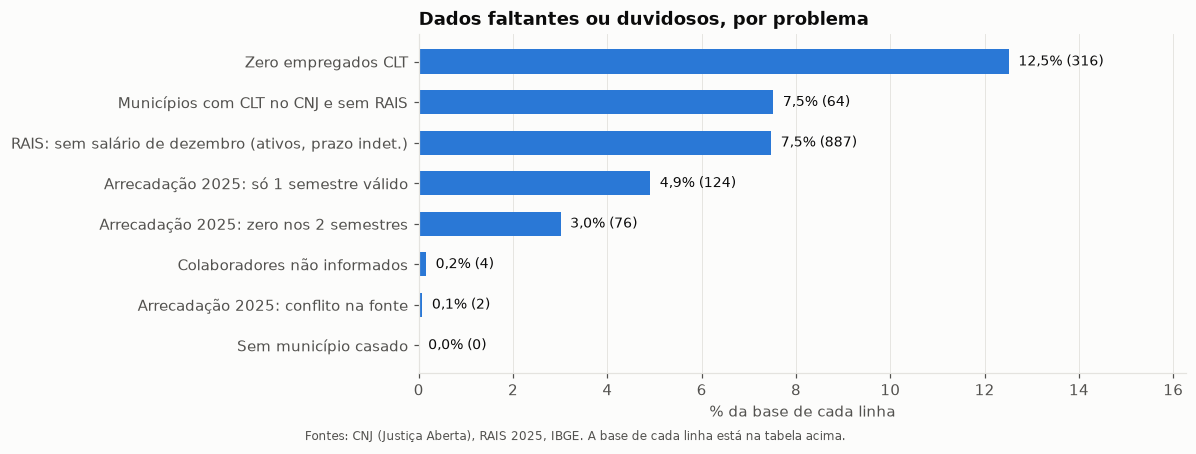

In [7]:
resumo = pd.concat([
    est.faltantes({
        "Arrecadação 2025: zero nos 2 semestres": sv.origem_receita.eq("zero_nos_dois_semestres"),
        "Arrecadação 2025: só 1 semestre válido": sv.origem_receita.eq("um_semestre"),
        "Arrecadação 2025: conflito na fonte": sv.origem_receita.eq("conflito_fonte"),
        "Colaboradores não informados": ~sv.colaboradores_informados.fillna(False).astype(bool),
        "Zero empregados CLT": sv.clt.eq(0),
        "Sem município casado": sem_mun,
    }).assign(base="serventias ativas"),
    est.faltantes({"RAIS: sem salário de dezembro (ativos, prazo indet.)": base.rem_dezembro.fillna(0).eq(0)})
      .assign(base="vínculos da RAIS"),
    est.faltantes({"Municípios com CLT no CNJ e sem RAIS": (com_cnj.clt_cnj > 0) & (com_cnj.vinc_rais == 0)})
      .assign(base="municípios com serventia"),
], ignore_index=True)
display(g.tabela(resumo, {"n": "int", "total": "int", "pct": "pct"}))

r = resumo.sort_values("pct")
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(r["problema"], 100 * r["pct"], color=g.AZUL["medio"], height=0.6)
for i, (v, n) in enumerate(zip(r["pct"], r["n"])):
    ax.text(100 * v + 0.2, i, f"{g.pct(v)} ({g.num(n)})", va="center", fontsize=9, color=g.TEXTO)
ax.set_xlim(0, 100 * r["pct"].max() * 1.3)
ax.grid(axis="y", visible=False)
ax.set_xlabel("% da base de cada linha")
ax.set_title("Dados faltantes ou duvidosos, por problema")
g.nota(fig, "Fontes: CNJ (Justiça Aberta), RAIS 2025, IBGE. A base de cada linha está na tabela acima.")
g.salvar(fig, "01_dados_faltantes_resumo")
plt.show()

**Como ler.** Barras maiores = problemas maiores. Atenção às bases diferentes: a linha da RAIS é sobre vínculos, e a dos municípios, sobre municípios.

**O que encontramos.** Os dois problemas de maior tamanho são **zero empregados CLT** (12,5% das serventias) e **municípios com CLT e sem RAIS** (7,5%). Para o enquadramento da classe, o problema relevante são as **78 indeterminadas (3,1%)** e as **124 com um semestre só (4,9%)**.

**Limitações.** Esta tabela não diz se o dado presente está **certo**; isso é tema das seções 7 (atípicos) e 8 (fontes cruzadas).

## 7. Valores atípicos (outliers)

**A pergunta.** Quais serventias têm receita, empregados ou passivo muito fora do padrão, e esses valores parecem **erro** ou são **reais**?

**O método: as "cercas" de Tukey em escala log.**
- **Mediana**: o valor do meio quando ordenamos todos (metade fica abaixo, metade acima).
- **Quartis**: Q1 é o valor abaixo do qual ficam 25% dos dados; Q3, o valor abaixo do qual ficam 75%. A distância **IQR = Q3 − Q1** mede a dispersão "do meio".
- **Cercas**: um valor é atípico se fica abaixo de Q1 − 1,5 × IQR ou acima de Q3 + 1,5 × IQR (critério clássico de John Tukey, o mesmo do gráfico de caixa; `config/analise.yaml`).
- **Escala log**: a receita vai de poucos mil a dezenas de milhões de reais. Na escala comum, metade da cauda seria "atípica". Por isso fazemos a conta com o **logaritmo na base 10** (log10 de 1.000 = 3; de 1.000.000 = 6): cada unidade é "10 vezes mais". O **zero** não tem logaritmo e é contado à parte (seção 3).

Exemplo pequeno: receitas de R$ 10 mil, 100 mil, 1 milhão, 10 milhões e 100 milhões têm log10 = 4, 5, 6, 7 e 8. Q1 = 5 e Q3 = 7, IQR = 2; as cercas ficam em 5 − 3 = 2 e 7 + 3 = 10, ou seja, entre R$ 100 e R$ 10 bilhões: nenhum é atípico, porque a cauda é "regular" em log.

Por que este método: não supõe que os dados seguem uma curva normal e não é puxado pelos próprios valores extremos (média e desvio-padrão seriam).

,variável,valores > 0,cerca inferior,cerca superior,abaixo,acima
0,Receita de referência (R$/semestre),2.447,"5.237,7","20.453.749,7",21,11
1,Empregados CLT,2.205,"0,4","31,2",0,52
2,Passivo estimado (R$),2.205,"2.757,1","1.061.292,6",0,44


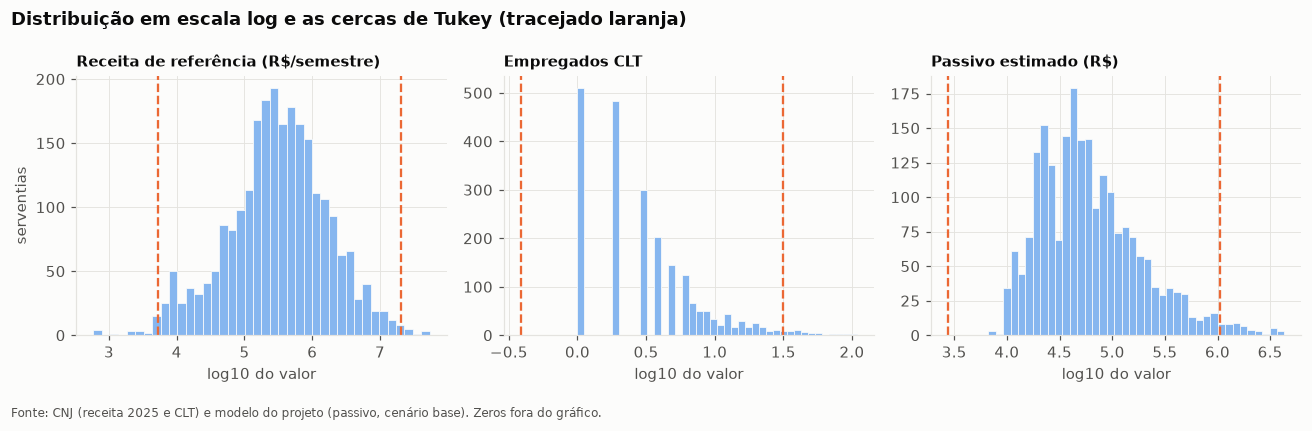

In [8]:
variaveis = {"receita_ref": "Receita de referência (R$/semestre)", "clt": "Empregados CLT", "passivo": "Passivo estimado (R$)"}
linhas = []
for col, nome in variaveis.items():
    s = sv[col]
    inf, sup = est.cercas_iqr(s)
    at = est.atipicos(s)
    linhas.append({"variável": nome, "valores > 0": int((s > 0).sum()), "cerca inferior": inf, "cerca superior": sup,
                   "abaixo": int((at & (s < inf)).sum()), "acima": int((at & (s > sup)).sum())})
cercas = pd.DataFrame(linhas)
display(g.tabela(cercas, {"valores > 0": "int", "cerca inferior": "num1", "cerca superior": "num1", "abaixo": "int", "acima": "int"}))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (col, nome) in zip(axes, variaveis.items()):
    s = sv[col][sv[col] > 0]
    inf, sup = est.cercas_iqr(sv[col])
    ax.hist(np.log10(s), bins=40, color=g.AZUL["claro"], edgecolor=g.SUPERFICIE, linewidth=0.5)
    for lim in (inf, sup):
        ax.axvline(np.log10(lim), color=g.CORES[1], linewidth=1.5, linestyle="--")
    ax.set_title(nome, fontsize=10)
    ax.set_xlabel("log10 do valor")
axes[0].set_ylabel("serventias")
fig.suptitle("Distribuição em escala log e as cercas de Tukey (tracejado laranja)", x=0.01, ha="left", fontweight="bold")
g.nota(fig, "Fonte: CNJ (receita 2025 e CLT) e modelo do projeto (passivo, cenário base). Zeros fora do gráfico.")
fig.tight_layout()
g.salvar(fig, "01_valores_atipicos_receita_clt_passivo")
plt.show()

Quem são os atípicos? Como o estudo é público e os dados vêm de fontes públicas, listamos as serventias pelo **CNS e município** (sem nome de pessoa).

In [9]:
cols = ["cns", "municipio", "situacao", "receita_ref", "origem_receita", "clt", "passivo"]
fmt = {"receita_ref": "reais", "clt": "int", "passivo": "reais"}
at_rec = est.atipicos(sv.receita_ref)
print("Receita atípica ALTA (as 11):")
display(g.tabela(sv[at_rec & (sv.receita_ref > sv.receita_ref.median())].sort_values("receita_ref", ascending=False)[cols], fmt))
print("Receita atípica BAIXA (as 10 menores):")
display(g.tabela(sv[at_rec & (sv.receita_ref < sv.receita_ref.median())].sort_values("receita_ref")[cols].head(10), fmt))
baixa = sv[at_rec & (sv.receita_ref < sv.receita_ref.median())]
print(f"Das {len(baixa)} com receita atípica baixa: {g.num(baixa.situacao.eq('vaga').sum())} vagas; "
      f"{g.num(baixa.origem_receita.eq('um_semestre').sum())} com um semestre só.")

Receita atípica ALTA (as 11):


,cns,municipio,situacao,receita_ref,origem_receita,clt,passivo
962,042986,Turmalina,vaga,"R$ 54,1 mi",media_2_semestres,0,R$ 0
2099,057091,Contagem,vaga,"R$ 43,9 mi",media_2_semestres,61,"R$ 1,5 mi"
46,032136,Uberlândia,provida,"R$ 42,2 mi",media_2_semestres,109,"R$ 4,3 mi"
178,033670,Belo Horizonte,provida,"R$ 35,3 mi",media_2_semestres,78,"R$ 3,2 mi"
85,032573,Uberlândia,provida,"R$ 26,7 mi",media_2_semestres,91,"R$ 3,6 mi"
183,033738,Belo Horizonte,provida,"R$ 25,6 mi",media_2_semestres,90,"R$ 3,7 mi"
45,032128,Belo Horizonte,provida,"R$ 24,9 mi",media_2_semestres,97,"R$ 4,0 mi"
652,039040,Betim,provida,"R$ 24,5 mi",media_2_semestres,57,"R$ 2,2 mi"
1872,054023,Pouso Alegre,provida,"R$ 23,4 mi",media_2_semestres,54,"R$ 1,4 mi"
2225,058644,Patrocínio,provida,"R$ 21,5 mi",media_2_semestres,35,"R$ 1,3 mi"


Receita atípica BAIXA (as 10 menores):


,cns,municipio,situacao,receita_ref,origem_receita,clt,passivo
1828,053538,Águas Vermelhas,vaga,R$ 586,um_semestre,0,R$ 0
2471,145367,Cataguases,vaga,R$ 643,media_2_semestres,1,"R$ 15,9 mil"
1311,047043,Pintópolis,vaga,R$ 682,media_2_semestres,0,R$ 0
1114,044669,Três Pontas,vaga,R$ 713,media_2_semestres,0,R$ 0
1827,053520,Santa Rita de Jacutinga,vaga,"R$ 1,2 mil",media_2_semestres,1,"R$ 22,8 mil"
1651,051714,Estrela do Indaiá,vaga,"R$ 2,0 mil",um_semestre,0,R$ 0
515,037499,Quartel Geral,vaga,"R$ 2,1 mil",media_2_semestres,0,R$ 0
1847,053728,Carmo do Rio Claro,vaga,"R$ 2,4 mil",media_2_semestres,3,"R$ 62,2 mil"
121,033019,Amparo do Serra,provida,"R$ 2,5 mil",um_semestre,0,R$ 0
1552,050559,Buritizeiro,vaga,"R$ 2,5 mil",media_2_semestres,1,"R$ 19,5 mil"


Das 21 com receita atípica baixa: 19 vagas; 5 com um semestre só.


**Como ler.** No gráfico, cada barra conta quantas serventias têm valores naquela faixa de log10; as linhas tracejadas são as cercas. Na tabela, as linhas são as serventias fora das cercas.

**O que encontramos.**
- **Receita:** 32 atípicas (11 acima de ≈ R$ 20 milhões por semestre e 21 abaixo de ≈ R$ 5 mil).
  - Das 11 **altas**, 10 são grandes cartórios de Belo Horizonte, Uberlândia, Contagem, Betim e outras cidades grandes, com dezenas de empregados CLT: parecem **reais**.
  - A **maior receita de MG** é uma exceção clara: a serventia **042986, de Turmalina** (vaga, Notas e Registro Civil, **zero CLT**), com média de R$ 54,1 milhões. Ela arrecadava entre R$ 10 mil e R$ 42 mil por semestre de 2021 a 2025-1 e declarou **R$ 108,1 milhões em 2025-2** (com 875 atos, número parecido com o dos outros semestres), voltando a R$ 34 mil em 2026-1. É quase certamente **erro de declaração**. A seção 7b procura casos assim de forma sistemática.
  - As **baixas** são serventias pequenas, 19 das 21 vagas: valores de poucos mil reais por semestre são plausíveis em municípios muito pequenos, mas também podem ser declaração incompleta.
- **Empregados CLT:** 52 acima de ≈ 31 CLT (os grandes cartórios). Nenhum abaixo da cerca, porque o zero é contado à parte.
- **Passivo:** 44 acima de ≈ R$ 1,06 milhão. Como o passivo é calculado a partir do CLT, os atípicos de passivo são quase os mesmos de CLT.

**O que significa para o Prov. 227.** Os atípicos **altos** são o coração do mercado: poucos cartórios grandes concentram o passivo (o notebook 02 mede quanto). Não devem ser removidos. Os **baixos** são Classe 1 (dispensados), e um erro neles não muda quem é obrigado.

**Limitações.** "Atípico" é um critério estatístico, não uma prova de erro. Não há outra fonte de receita por serventia além do CNJ (o BI da seção 8 é do mesmo órgão). E a cerca olha MG inteira: um erro que leva uma serventia pequena a um valor "normal para MG" (como R$ 3 milhões) não aparece aqui. Por isso a seção 7b compara cada serventia **com o próprio histórico**.

## 7b. Saltos na série de cada serventia

**A pergunta.** Quantas serventias têm um semestre **muito fora do próprio histórico**, e isso pode mudar quem é obrigado ao seguro?

**O método.** Para cada serventia e cada semestre, calculamos a **mediana dos 4 semestres anteriores** dela (dois anos) e a **razão** entre o valor do semestre e essa mediana. Marcamos como **salto** a razão de **10 vezes ou mais** (para cima ou para baixo). Os zeros ficam de fora (já contados na seção 1). Os parâmetros (4 semestres, 10 vezes) estão em `config/analise.yaml`, como `fonte: suposição`: um corte largo, para pegar só o grosseiro.

Exemplo: semestres anteriores de R$ 10, 12, 11 e 13 mil → mediana R$ 11,5 mil. Se o semestre seguinte vem com R$ 1,3 milhão, a razão é 113: salto.

**Sensibilidade (não muda o painel).** Para as serventias com salto em 2025, recalculamos a receita de referência **sem os semestres com salto** (a média dos semestres de 2025 que sobram; se não sobrar nenhum, a média de 2024) e vemos quantas mudariam de classe **nas duas direções**: obrigadas que cairiam para a Classe 1 (saem do universo) e providas da Classe 1 que subiriam (entram).

In [10]:
from src.analise import enquadramento

saltos = est.saltos(ar)
print(f"Saltos de 10× ou mais: {g.num(len(saltos))} serventia-semestres desde 2009; por ano, a partir de 2019:")
display(saltos[saltos.ano >= 2019].groupby("ano").agg(saltos=("cns", "size"), serventias=("cns", "nunique")).T)

s25 = saltos[saltos.ano == 2025]
persistem = s25[s25.semestre == 2].cns.isin(saltos[saltos.periodo == "2026-1"].cns)
print(f"Em 2025: {g.num(len(s25))} saltos em {g.num(s25.cns.nunique())} serventias. Dos {g.num((s25.semestre == 2).sum())} "
      f"saltos de 2025-2, {g.num(persistem.sum())} continuam em 2026-1 (o novo nível se mantém).")

alt = sv[sv.cns.isin(s25.cns)].merge(enquadramento.receita_sem_saltos(ar, saltos, 2025), left_on="cns", right_index=True)
alt["classe_sem_saltos"] = enquadramento.classe_pela_receita(alt["receita_sem_saltos"])
display(pd.crosstab(alt["classe"], alt["classe_sem_saltos"], rownames=["classe (painel)"], colnames=["classe sem os saltos"]))

# as duas direções: obrigadas que cairiam para a Classe 1 (saem) e providas da Classe 1 que subiriam (entram)
viram_1 = alt[(alt.peso_universo > 0) & (alt.classe_sem_saltos == "1")]
saem_da_1 = alt[(alt.classe == "1") & (alt.situacao == "provida") & alt.classe_sem_saltos.isin(["2", "3"])]
print(f"Saem do universo: {len(viram_1)}; entram (providas da Classe 1 que subiriam sem os saltos): {len(saem_da_1)} "
      f"({', '.join(saem_da_1.cns)}). Efeito líquido: {len(saem_da_1) - len(viram_1):+d} obrigadas.")
efeito = pd.DataFrame({
    "painel (base)": [sv.peso_universo.sum(), sv.n_deficit.sum(), sv.valor_descoberto.sum()],
    "saem": [viram_1.peso_universo.sum(), viram_1.n_deficit.sum(), viram_1.valor_descoberto.sum()],
}, index=["obrigadas (≈)", "com déficit (≈)", "déficit (R$)"])
efeito["entram"] = [float(len(saem_da_1)), np.nan, np.nan]   # déficit de quem entra: o modelo não o calcula na Classe 1
efeito["variação"] = (efeito["entram"].fillna(0) - efeito["saem"]) / efeito["painel (base)"]
display(g.tabela(efeito.reset_index(names="número"), {"painel (base)": "num1", "saem": "num1", "entram": "num1",
                                                     "variação": "pct"}))

zero_antes = ar[(ar.periodo == "2025-1") & (ar.arrecadacao == 0)].cns
print(f"Das {len(viram_1)} serventias do universo que mudariam para a Classe 1, {g.num(viram_1.cns.isin(zero_antes).sum())} "
      "declararam R$ 0 em 2025-1 (a receita do painel vem só do semestre do salto).")
print("As serventias que mudariam de lado no limite da Classe 1:")
display(g.tabela(pd.concat([viram_1.assign(mudanca="sai do universo"), saem_da_1.assign(mudanca="entra no universo")])
                 [["cns", "municipio", "situacao", "mudanca", "clt", "receita_ref", "receita_sem_saltos", "passivo"]]
                 .sort_values("receita_ref", ascending=False),
                 {"clt": "int", "receita_ref": "reais", "receita_sem_saltos": "reais", "passivo": "reais"}))

Saltos de 10× ou mais: 526 serventia-semestres desde 2009; por ano, a partir de 2019:


ano,2019,2020,2021,2022,2023,2024,2025,2026
saltos,15,16,19,14,15,38,45,44
serventias,14,13,17,11,12,28,43,44


Em 2025: 45 saltos em 43 serventias. Dos 32 saltos de 2025-2, 18 continuam em 2026-1 (o novo nível se mantém).


classe sem os saltos,1,2,3
classe (painel),,,
1,13,1,0
2,5,7,0
3,14,2,1


Saem do universo: 12; entram (providas da Classe 1 que subiriam sem os saltos): 1 (047001). Efeito líquido: -11 obrigadas.


,número,painel (base),saem,entram,variação
0,obrigadas (≈),"1.121,3","12,0","1,0","-1,0%"
1,com déficit (≈),"486,0","4,2",—,"-0,9%"
2,déficit (R$),"36.873.873,9","243.312,7",—,"-0,7%"


Das 12 serventias do universo que mudariam para a Classe 1, 8 declararam R$ 0 em 2025-1 (a receita do painel vem só do semestre do salto).
As serventias que mudariam de lado no limite da Classe 1:


,cns,municipio,situacao,mudanca,clt,receita_ref,receita_sem_saltos,passivo
122,033027,Andradas,provida,sai do universo,16,"R$ 6,2 mi","R$ 61,6 mil","R$ 434,6 mil"
1890,054445,Ibiraci,provida,sai do universo,9,"R$ 3,6 mi","R$ 43,4 mil","R$ 163,7 mil"
706,039776,Porteirinha,provida,sai do universo,11,"R$ 3,2 mi","R$ 120,8 mil","R$ 125,8 mil"
2301,059626,Itabirito,provida,sai do universo,7,"R$ 2,4 mi","R$ 177,5 mil","R$ 118,4 mil"
2131,057554,Divino,provida,sai do universo,10,"R$ 2,0 mi","R$ 32,5 mil","R$ 90,0 mil"
2122,057380,Ponte Nova,provida,sai do universo,12,"R$ 1,8 mi","R$ 247,6 mil","R$ 239,7 mil"
2196,058339,Januária,provida,sai do universo,12,"R$ 1,8 mi","R$ 127,4 mil","R$ 124,4 mil"
2125,057455,Lajinha,provida,sai do universo,7,"R$ 1,8 mi","R$ 55,7 mil","R$ 76,3 mil"
1908,054767,Cambuí,provida,sai do universo,12,"R$ 1,8 mi","R$ 34,9 mil","R$ 211,7 mil"
2483,152322,Pedralva,provida,sai do universo,4,"R$ 994,9 mil","R$ 23,2 mil","R$ 85,5 mil"


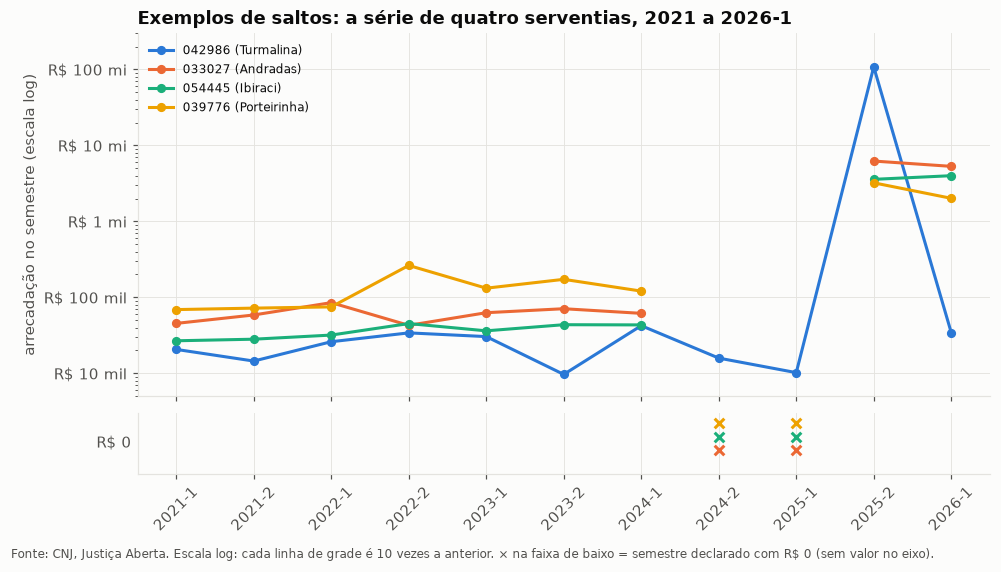

In [11]:
exemplos = ["042986"] + viram_1.sort_values("receita_ref", ascending=False).cns.head(3).tolist()
fig, (ax, faixa) = plt.subplots(2, 1, figsize=(10, 5.2), sharex=True, gridspec_kw={"height_ratios": [6, 1], "hspace": 0.08})
for i, cns in enumerate(exemplos):
    x = ar[(ar.cns == cns) & (ar.ano >= 2021)]
    ax.plot(x.periodo, x.arrecadacao.where(x.arrecadacao > 0), marker="o", markersize=5, color=g.CORES[i],
            label=f"{cns} ({sv.set_index('cns').municipio[cns]})")
    zeros = x[x.arrecadacao == 0]   # o zero não tem lugar na escala log: vai para a faixa de baixo, sem eixo de valor
    faixa.scatter(zeros.periodo, [i] * len(zeros), marker="x", s=40, color=g.CORES[i])
ax.set_yscale("log")
ax.set_ylim(5e3, 3e8)
g.eixo_reais(ax)
ax.set_ylabel("arrecadação no semestre (escala log)")
ax.set_title("Exemplos de saltos: a série de quatro serventias, 2021 a 2026-1")
ax.legend(loc="upper left", fontsize=8)
faixa.set_ylim(-0.7, len(exemplos) - 0.3)
faixa.set_yticks([])
faixa.grid(axis="y", visible=False)
faixa.set_ylabel("R$ 0", rotation=0, ha="right", va="center")
faixa.tick_params(axis="x", rotation=45)
g.nota(fig, "Fonte: CNJ, Justiça Aberta. Escala log: cada linha de grade é 10 vezes a anterior. "
            "× na faixa de baixo = semestre declarado com R$ 0 (sem valor no eixo).")
g.salvar(fig, "01_saltos_arrecadacao_exemplos")
plt.show()

**Como ler.** A primeira tabela conta os saltos por ano. A tabela cruzada mostra a classe de cada serventia com salto em 2025 no painel (linhas) e a classe que ela teria sem os semestres com salto (colunas): o que fica fora da diagonal muda de classe. A tabela de efeito mostra quantas obrigadas saem e quantas entram, e o efeito líquido sobre os números do painel. No gráfico, cada linha é uma serventia; em escala log, um salto de 10 vezes é a distância de uma linha de grade; os semestres declarados com R$ 0 aparecem como × na faixa de baixo (o zero não tem lugar na escala log).

**O que encontramos.**
- Os saltos **aumentam em 2024 e 2025** (38 e 45, contra 14 a 19 por ano entre 2019 e 2023), o mesmo período em que os zeros sobem (seção 1). Em 2026-1 já são 44, quase todos para cima.
- Um padrão se repete nos exemplos do gráfico: em Andradas, Ibiraci e Porteirinha, o salto de 2025-2 vem **logo depois de dois semestres declarados com R$ 0** (2024-2 e 2025-1). Para essas serventias, a receita de referência do painel sai **só de 2025-2** (regra "um semestre", D-010), que é justamente o semestre do salto. Das 12 obrigadas que mudariam para a Classe 1 (abaixo), **8** têm esse padrão (R$ 0 em 2025-1 e salto em 2025-2). Uma leitura possível: a serventia deixou de declarar e depois lançou num semestre só um valor acumulado ou digitado errado; outra é uma mudança real de porte.
- Em muitos casos o novo nível **se mantém** em 2026-1 (18 dos 32 saltos de 2025-2). Isso pode ser **mudança real** (por exemplo, uma serventia que passou a acumular as atribuições de outra) e não erro; os dados públicos não dizem qual é o caso.
- O caso de Turmalina (R$ 108 milhões num semestre) é erro quase certo, mas a serventia é **vaga**, fica fora do universo do Prov. 227 (peso 0) e tem zero CLT: **não mexe** nos 10 números. Ela infla, porém, o total de MG de 2025-2 em ≈ R$ 108 milhões (3,5%), o que importa para a série do notebook 02.
- **Se** todos os saltos de 2025 fossem erro, **12 obrigadas** passariam à Classe 1 e **1 provida** da Classe 1 subiria para a Classe 2: a 047001 (Caldas), cujo salto foi em 2025-1; sem esse semestre, a receita de referência passa a ser só a de 2025-2, que é maior (R$ 365 mil, contra a média de R$ 295 mil do painel). O efeito líquido é de **−11 obrigadas (≈ −1,0%)**, e o déficit cairia ≈ 0,7%. É um efeito **pequeno**.

**O que significa para o Prov. 227.** Os números do painel são robustos a esse problema: no pior caso, mudam cerca de 1%. Mas a qualidade da declaração de 2025 merece uma conferência do autor, porque é o ano que define o primeiro ciclo de obrigação.

**Limitações.** O critério de 10 vezes é uma suposição; com um corte menor, apareceriam mais casos (e mais crescimento real seria marcado como suspeito). A recontagem da classe é só uma sensibilidade: não sabemos qual valor é o verdadeiro. O déficit de quem entraria (047001) não é calculado aqui, porque o modelo não calcula déficit para a Classe 1; com 2 CLT e R$ 54 mil de passivo, ele seria pequeno.

## 8. As fontes concordam entre si?

**A pergunta.** Quando duas fontes medem a mesma coisa, elas dão o mesmo número?

**O método.** Três comparações:
1. **Totais de MG**: serventias (CNJ × CNPJ), empregados (CNJ × RAIS) e arrecadação (API do CNJ × BI do CNJ).
2. **Empregados por município** (CNJ × RAIS), com a **correlação de Spearman**. *Correlação* mede se duas medidas andam juntas: vai de −1 (uma sobe, a outra desce) a +1 (sobem juntas); 0 = sem relação. A de **Spearman** usa a **posição** de cada valor na fila (1º, 2º, 3º...) em vez do valor, por isso não é dominada por Belo Horizonte, que tem muito mais empregados que as outras cidades. Exemplo: se as cidades A, B e C são, nessa ordem, 1ª, 2ª e 3ª nas duas fontes, a correlação é 1, mesmo que os números sejam diferentes.
3. **Arrecadação por serventia** (API × BI), semestre a semestre: quantas são iguais (diferença menor que R$ 1), quantas diferem mais de 1% e quantas faltam no BI.

In [12]:
reconc = ler("SELECT checagem, fonte_a, valor_a, fonte_b, valor_b, indicador, tolerancia, status FROM qualidade.reconciliacoes "
             "WHERE checagem LIKE 'serventias ativas%' OR checagem LIKE 'empregados: RAIS%'", con=con)
display(g.tabela(reconc, {"valor_a": "int", "valor_b": "int", "indicador": "pct", "tolerancia": "pct"}))

bi = dados.arrecadacao_bi(con)
cruz = ar.merge(bi, on=["cns", "ano", "semestre"], how="left")
cruz["dif"] = cruz["arrecadacao"] - cruz["arrecadacao_bi"]
cruz["dif_rel"] = cruz["dif"].abs() / cruz["arrecadacao_bi"].where(cruz["arrecadacao_bi"] > 0)
comp = cruz[cruz.ano >= 2023].groupby("periodo").agg(
    api=("arrecadacao", "sum"), bi=("arrecadacao_bi", "sum"),
    faltam_no_bi=("arrecadacao_bi", lambda s: int(s.isna().sum())),
    iguais=("dif", lambda s: int((s.abs() < 1).sum())),
    dif_mais_1pct=("dif_rel", lambda s: int((s > 0.01).sum())))
comp["api_sobre_bi"] = comp["api"] / comp["bi"] - 1
display(g.tabela(comp.reset_index(), {"api": "reais", "bi": "reais", "faltam_no_bi": "int", "iguais": "int",
                                      "dif_mais_1pct": "int", "api_sobre_bi": "pct"}))

,checagem,fonte_a,valor_a,fonte_b,valor_b,indicador,tolerancia,status
0,serventias ativas: CNPJ × CNJ (MG),"CNPJ ativos, CNAE principal 6912-5/00",2.923,CNJ ativas,2.525,"15,8%","5,0%",aviso
1,empregados: RAIS × CNJ (MG),RAIS vínculos ativos em 31/12/2025,12.347,CNJ colaboradores CLT,12.134,"1,8%","5,0%",ok


,periodo,api,bi,faltam_no_bi,iguais,dif_mais_1pct,api_sobre_bi
0,2023-1,"R$ 1,8 bi","R$ 1,8 bi",0,2.525,0,"0,0%"
1,2023-2,"R$ 2,2 bi","R$ 2,2 bi",1,2.520,4,"-0,1%"
2,2024-1,"R$ 2,0 bi","R$ 2,1 bi",0,2.513,12,"-0,9%"
3,2024-2,"R$ 2,5 bi","R$ 2,5 bi",0,2.518,4,"0,0%"
4,2025-1,"R$ 2,4 bi","R$ 2,4 bi",0,2.511,2,"0,2%"
5,2025-2,"R$ 3,1 bi","R$ 3,1 bi",168,2.351,2,"2,2%"
6,2026-1,"R$ 3,2 bi","R$ 3,2 bi",58,2.466,1,"0,1%"


Correlação de Spearman CNJ × RAIS por município: 0,926 (821 municípios)


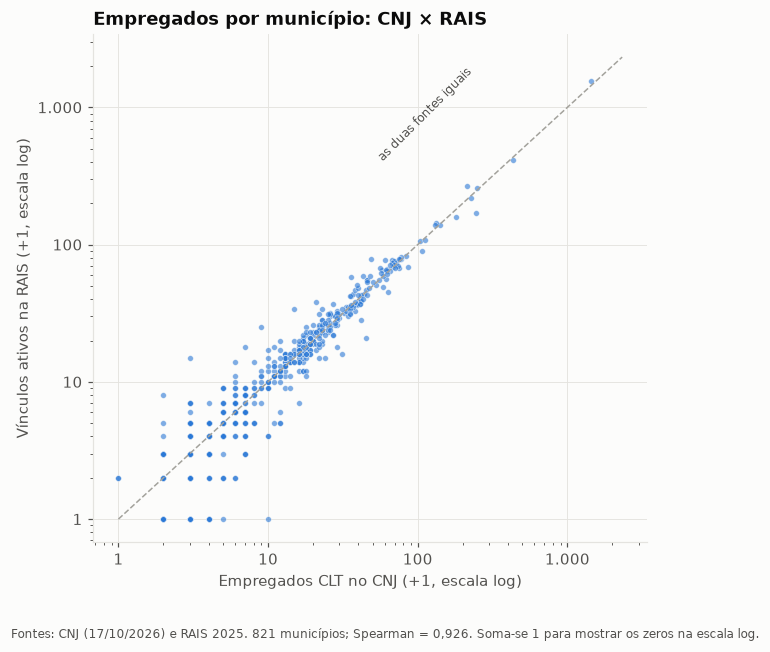

In [13]:
m = rec[(rec.clt_cnj > 0) | (rec.vinc_rais > 0)]
rho = est.correlacoes(m, ["clt_cnj", "vinc_rais"]).iloc[0]
print(f"Correlação de Spearman CNJ × RAIS por município: {g.num(rho.rho, 3)} ({g.num(rho.n)} municípios)")

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(m.clt_cnj + 1, m.vinc_rais + 1, s=14, color=g.CORES[0], alpha=0.6, edgecolor=g.SUPERFICIE, linewidth=0.4)
lim = [1, max(m.clt_cnj.max(), m.vinc_rais.max()) * 1.5]
ax.plot(lim, lim, color=g.CINZA, linewidth=1, linestyle="--")
ax.annotate("as duas fontes iguais", (300, 300), xytext=(-10, 12), textcoords="offset points", color=g.TEXTO_2,
            fontsize=8, ha="right", rotation=45)
ax.set_xscale("log"); ax.set_yscale("log")
g.eixo_num(ax, "x"); g.eixo_num(ax, "y")
ax.set_xlabel("Empregados CLT no CNJ (+1, escala log)"); ax.set_ylabel("Vínculos ativos na RAIS (+1, escala log)")
ax.set_title("Empregados por município: CNJ × RAIS")
g.nota(fig, f"Fontes: CNJ (17/10/2026) e RAIS 2025. {len(m)} municípios; Spearman = {g.num(rho.rho, 3)}. "
            "Soma-se 1 para mostrar os zeros na escala log.")
g.salvar(fig, "01_empregados_cnj_x_rais_por_municipio")
plt.show()

In [14]:
print("Serventias com arrecadação diferente em mais de 1% entre a API e o BI (2024 e 2025):")
dif = cruz[(cruz.ano >= 2024) & (cruz.dif_rel > 0.01)].merge(sv[["cns", "municipio", "situacao"]], on="cns")
display(g.tabela(dif[["periodo", "cns", "municipio", "situacao", "arrecadacao", "arrecadacao_bi", "dif_rel", "conflito_fonte"]]
                 .sort_values(["periodo", "dif_rel"], ascending=[True, False]),
                 {"arrecadacao": "reais", "arrecadacao_bi": "reais", "dif_rel": "pct"}))

Serventias com arrecadação diferente em mais de 1% entre a API e o BI (2024 e 2025):


,periodo,cns,municipio,situacao,arrecadacao,arrecadacao_bi,dif_rel,conflito_fonte
1,2024-1,034355,Baldim,vaga,"R$ 261,5 mil","R$ 570,5 mil","54,2%",True
2,2024-1,034900,Cristina,provida,"R$ 136,5 mil","R$ 273,0 mil","50,0%",False
5,2024-1,038448,Astolfo Dutra,vaga,"R$ 240,5 mil","R$ 481,1 mil","50,0%",False
6,2024-1,038620,Passos,provida,"R$ 10,7 mi","R$ 21,3 mi","50,0%",False
7,2024-1,040915,Virginópolis,provida,"R$ 533,6 mil","R$ 1,1 mi","50,0%",False
8,2024-1,042002,Formiga,provida,"R$ 507,1 mil","R$ 1,0 mi","50,0%",False
14,2024-1,054106,Botelhos,provida,"R$ 619,1 mil","R$ 1,2 mi","50,0%",False
17,2024-1,058503,Camanducaia,provida,"R$ 2,7 mi","R$ 5,5 mi","50,0%",False
18,2024-1,058958,Campestre,provida,"R$ 471,9 mil","R$ 943,8 mil","50,0%",False
19,2024-1,059139,Itaúna,provida,"R$ 595,7 mil","R$ 1,2 mi","50,0%",False


**Como ler.** Na primeira tabela, o "indicador" é a diferença relativa entre as fontes, comparada com a tolerância do projeto. No gráfico, cada ponto é um município; a linha tracejada é onde as fontes dariam o mesmo número.

**O que encontramos.**
- **Empregados:** a RAIS soma 12.347 vínculos ativos e o CNJ, 12.134 CLT: **1,8% de diferença** no total de MG. Por município, a correlação de Spearman é **0,93** (821 municípios); a maior parte dos pontos fica perto da diagonal. Os pontos no eixo de baixo e no da esquerda são os municípios com zero numa das fontes (seção 4).
- **Serventias:** o CNPJ tem **2.923** estabelecimentos ativos de cartório e o CNJ, **2.525** serventias ativas (+15,8%). **Hipótese** (não verificada nos dados): o CNPJ guarda CNPJs que não foram baixados depois que a serventia foi extinta ou mudou de titular. Seja qual for a causa, o CNJ é a fonte certa para a contagem, porque é o cadastro oficial das serventias.
- **Arrecadação, API × BI:** praticamente **igual** serventia a serventia: em cada semestre, mais de 99% das serventias presentes nas duas fontes têm a mesma arrecadação (diferença < R$ 1). As exceções:
  - em **2025-2**, **168 serventias faltam no BI** (o BI estava incompleto na exportação; por isso a tolerância desse semestre é maior);
  - em **2024-1**, 10 serventias têm no BI **exatamente o dobro** do valor da API (diferença de 50%): parece o BI somando duas vezes o mesmo semestre. Não afeta o enquadramento (que usa 2025);
  - em **2025**, 4 serventias: 2 com conflito na fonte (já indeterminadas) e 2 em que a API traz **muito mais** que o BI em 2025-2. Uma delas, a **035030 (Candeias, Protesto)**, tem R$ 360 mil na API e R$ 93 mil no BI: pela API, a média de 2025 é R$ 308 mil (**Classe 2, obrigada**); pelo BI, seria R$ 174 mil (**Classe 1, dispensada**). Como tem zero CLT, o passivo é zero e o efeito no mercado é só de **uma serventia a menos** no universo. A outra, 050914 (São João Evangelista), fica na Classe 2 nas duas fontes.

**O que significa para o Prov. 227.** A receita usada no enquadramento (API) bate com o BI, os empregados batem com a RAIS no total e a contagem de serventias vem da fonte certa. Os três insumos principais do modelo são **consistentes entre fontes**.

**Limitações.** A API e o BI são do mesmo órgão (CNJ) e podem ter a mesma origem: concordar entre si não prova que o valor declarado pelo cartório está certo. A RAIS não liga ao CNS, então a comparação de empregados é só por município.

## 9. Conclusão: o que é confiável, o que é estimado e o tamanho de cada problema

In [15]:
conclusao = pd.DataFrame([
    ("Cadastro e situação das serventias (CNJ)", "confiável", "0 sem município (checado no cadastro); CNPJ tem +15,8%, não é usado na contagem"),
    ("Arrecadação semestral (CNJ)", "confiável", "API = BI em mais de 99% das serventias por semestre"),
    ("Receita de referência 2025 / classe", "confiável com lacuna", "78 indeterminadas (3,1%) e 124 com 1 semestre (4,9%)"),
    ("Zeros na arrecadação de 2025", "problema a acompanhar", "5,3% e 5,7% por semestre, contra 1% a 2% entre 2018 e 2024-1"),
    ("Saltos de 10× na série de 2025", "problema a acompanhar",
     f"45 saltos em 43 serventias; no pior caso, {len(saem_da_1) - len(viram_1):+d} obrigadas "
     f"({len(viram_1)} saem, {len(saem_da_1)} entra)"),
    ("Erros pontuais de declaração", "corrigir na fonte", "042986 (R$ 108 mi em 2025-2; fora do universo); 035030 (API ≠ BI; muda a classe)"),
    ("Empregados CLT (CNJ)", "confiável", "1,8% de diferença da RAIS em MG; 4 não informadas; 316 com zero CLT"),
    ("Salário e tempo de casa (RAIS)", "estimado por município", "7,5% dos vínculos sem remuneração de dezembro (vazio); 64 municípios sem RAIS"),
    ("Passivo por serventia", "estimado (modelo)", "depende do CLT do CNJ e da distribuição da RAIS do município/região"),
], columns=["dado", "avaliação", "tamanho do problema"])
with pd.option_context("display.max_colwidth", None):
    display(conclusao)

,dado,avaliação,tamanho do problema
0,Cadastro e situação das serventias (CNJ),confiável,"0 sem município (checado no cadastro); CNPJ tem +15,8%, não é usado na contagem"
1,Arrecadação semestral (CNJ),confiável,API = BI em mais de 99% das serventias por semestre
2,Receita de referência 2025 / classe,confiável com lacuna,"78 indeterminadas (3,1%) e 124 com 1 semestre (4,9%)"
3,Zeros na arrecadação de 2025,problema a acompanhar,"5,3% e 5,7% por semestre, contra 1% a 2% entre 2018 e 2024-1"
4,Saltos de 10× na série de 2025,problema a acompanhar,"45 saltos em 43 serventias; no pior caso, -11 obrigadas (12 saem, 1 entra)"
5,Erros pontuais de declaração,corrigir na fonte,042986 (R$ 108 mi em 2025-2; fora do universo); 035030 (API ≠ BI; muda a classe)
6,Empregados CLT (CNJ),confiável,"1,8% de diferença da RAIS em MG; 4 não informadas; 316 com zero CLT"
7,Salário e tempo de casa (RAIS),estimado por município,"7,5% dos vínculos sem remuneração de dezembro (vazio); 64 municípios sem RAIS"
8,Passivo por serventia,estimado (modelo),depende do CLT do CNJ e da distribuição da RAIS do município/região


**Em uma frase:** os dados de origem de MG são **completos e coerentes entre as fontes**; o ponto fraco é a **declaração de 2025**, o ano que define quem é obrigado ao seguro: 3,1% das serventias sem classe calculável, mais zeros e mais saltos que nos anos anteriores. O efeito disso nos números do painel é pequeno (cerca de 1% no universo, no pior caso: −11 obrigadas).

**O que acompanhar:**
1. Os **zeros e saltos de 2025**: na próxima coleta, conferir se as serventias corrigiram a declaração (se sim, parte das 78 indeterminadas ganha classe, e alguns saltos podem sumir).
2. Os casos pontuais **042986** e **035030** (seções 7 e 8): conferir no Justiça Aberta.
3. Os **vínculos afastados** da RAIS: se o perfil deles for diferente, o passivo pode estar um pouco subestimado (efeito a medir no notebook 08, de sensibilidade).
4. O **BI do 2º semestre de 2025**: reexportar quando estiver completo, para fechar a conferência.

**Para o cálculo do painel:** nada aqui obriga a mudar os 10 números agora. Duas sugestões para o autor decidir: (a) uma checagem de qualidade de **saltos** no pipeline, como aviso; (b) uma regra para semestres com salto grosseiro no enquadramento (por exemplo, tratar como conflito, D-014).

> **Atualização (2026-10-28, D-046): premissas v3.** As saídas deste notebook são da carga com as premissas v2. Desde a D-046, a chance de déficit e a parte descoberta vêm da capacidade de pagar do titular (M1, notebook 10), e não mais de suposição. Os números 1 a 5 e o 10 não mudaram; o déficit, a IS e o prêmio caíram 7,5% (prêmio de R$ 368,7 mil para R$ 341,1 mil), e a contagem "com déficit" foi de ≈ 486 para ≈ 148. O que este notebook diz sobre dados, classes, passivo e universo continua valendo; os valores de déficit e prêmio atuais estão no `notebooks/09_conclusoes_lacunas.ipynb`. A D-046 também manteve o valor declarado nos semestres com salto grosseiro (com aviso no pipeline e sensibilidade "sem os saltos") e deixou os dados como os de 17 e 18/10.